<a href="https://colab.research.google.com/github/Erilocshada/erilocshada-PCVK-2026-course/blob/main/18_P7_Muhammad_Pearl_Ocshada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Cell Identitas**

In [ ]:
NAMA = 'Muhammad Pearl Ocshada'
NIM = '244107020064'
print(NAMA, NIM)

Muhammad Pearl Ocshada 244107020064


# **Praktikum 7 - Segmentasi Citra dengan Thresholding**
## **D1 - Tugas Individu**
**A. Load Data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**B. Import Library yang digunakan**

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

**C. Membuat Global Thresold**
  - BINARY
  - BINARY_INV
  - TRUNC
  - TOZERO
  - TOZERO_INV

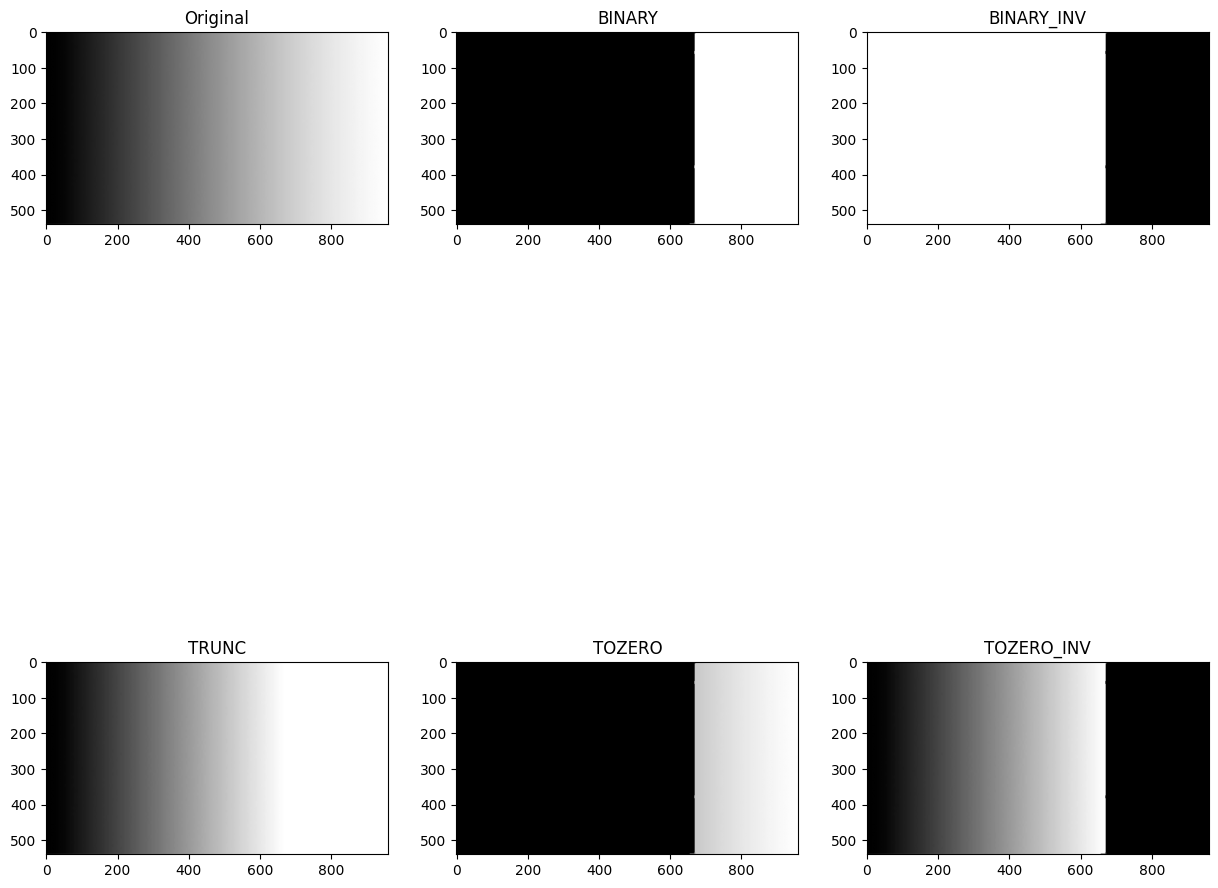

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/P7/gradient.jpg', 0) #0 - membaca sebagai greyscale (1 channel)
t = 200

mask = img > t

binary = np.where(mask, 255, 0).astype('uint8')
binary_inv = np.where(mask, 0, 255).astype('uint8')
trunc = np.where(mask, t, img).astype('uint8')
tozero = np.where(mask, img, 0).astype('uint8')
tozero_inv = np.where(mask, 0, img).astype('uint8')

images = [img, binary, binary_inv, trunc, tozero, tozero_inv]
titles = ['Original', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']

plt.figure(figsize=(15, 15))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
plt.show()

**D. Membuat Adaptive Threshold**
- Global Threshold (T=127)
- Adaptive Mean - Manual
- Adaptive Gaussian - Manual

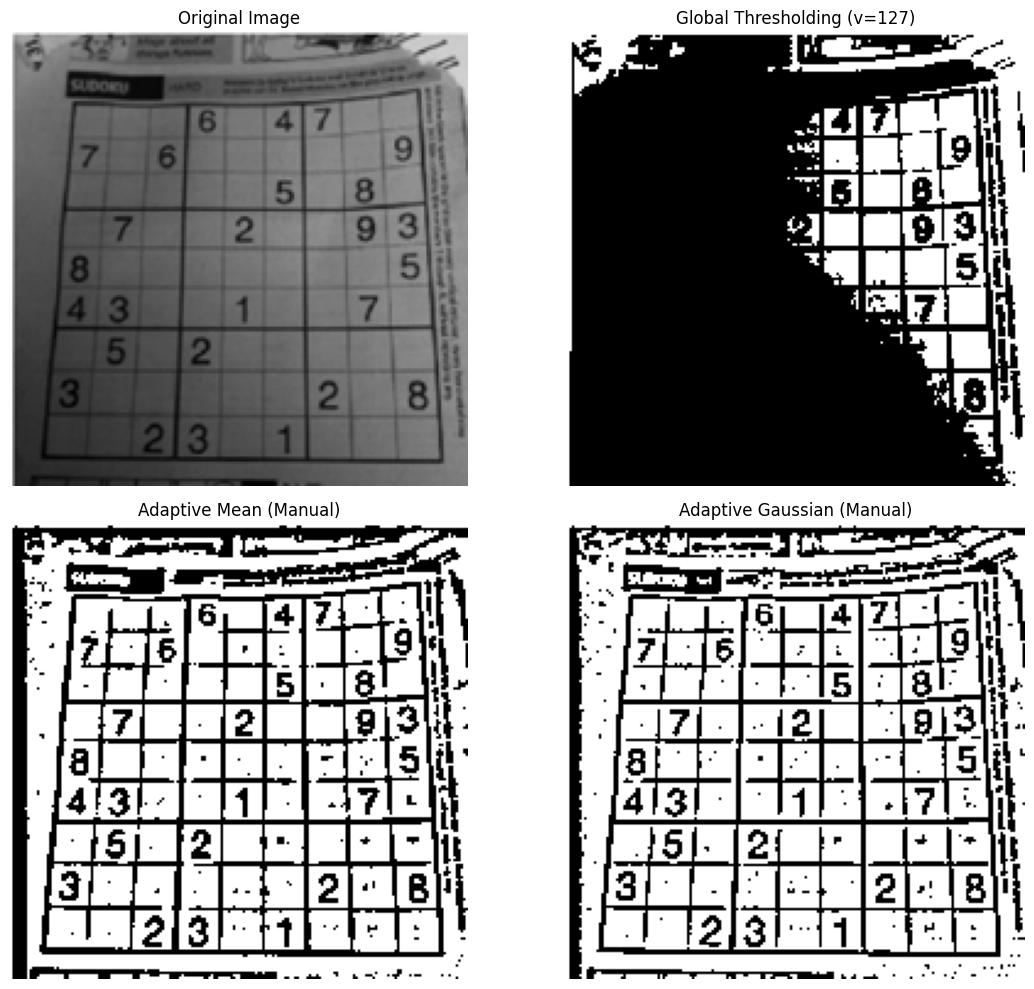

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar dalam format grayscale
img = cv.imread('/content/drive/MyDrive/PCVK/P7/sudoku.png', 0)

# Inisialisasi parameter
t = 127
window = 11
c = 2
sigma = 2

# 1. Global Threshold
global_thresh = np.where(img > t, 255, 0).astype('uint8')

# Pad image untuk menangani area pinggir (border)
pad_size = window // 2
img_padded = np.pad(img, pad_size, mode='edge')

h, w = img.shape
adaptive_mean = np.zeros_like(img)
adaptive_gaussian = np.zeros_like(img)

# Membuat kernel Gaussian manual
x, y = np.mgrid[-pad_size:pad_size+1, -pad_size:pad_size+1]
g_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
g_kernel = g_kernel / g_kernel.sum()

# Perhitungan manual menggunakan sliding window
for i in range(h):
    for j in range(w):
        # Ambil wilayah lokal (neighborhood)
        local_region = img_padded[i:i+window, j:j+window]

        # Rumus Manual Adaptive Mean: Rata-rata lokal - C
        mean_val = np.mean(local_region)
        thresh_mean = mean_val - c
        adaptive_mean[i, j] = 255 if img[i, j] > thresh_mean else 0

        # Rumus Manual Adaptive Gaussian: Weighted sum dengan kernel Gaussian - C
        gaussian_val = np.sum(local_region * g_kernel)
        thresh_gaussian = gaussian_val - c
        adaptive_gaussian[i, j] = 255 if img[i, j] > thresh_gaussian else 0

# Menampilkan hasil visualisasi
titles = ['Original Image', 'Global Thresholding (v=127)', 'Adaptive Mean (Manual)', 'Adaptive Gaussian (Manual)']
images = [img, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(12, 10))
for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

**E. Buat Otsu Threshold tanpa library dan tampilkan nilai threshold menggunakan otsu's**


Otsu Threshold: 114


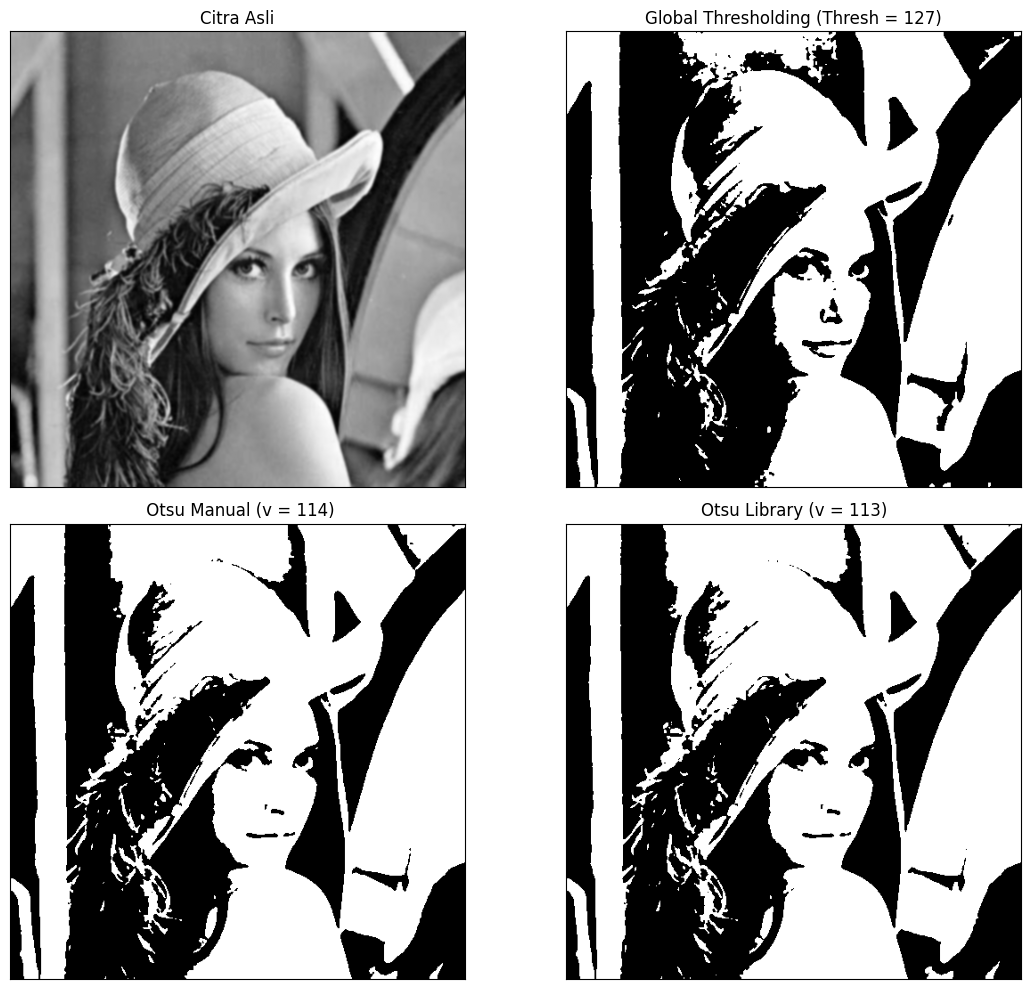

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK/P7/lena.jpg',0)
blur = cv.GaussianBlur(img,(5,5),0)
t=127


def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print("Otsu Threshold:", final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
ret, otsu_library = cv.threshold(blur,0,255,cv.THRESH_BINARY + cv.THRESH_OTSU)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', ' Otsu Manual (v = ' + str(otsu_thresh) + ')', 'Otsu Library (v = '+ str(int(ret)) + ')']
citra3 = [blur, th1, otsu_biner, otsu_library]

plt.figure(figsize = (12, 10))
for i in range(len(citra3)):
    plt.subplot(2, 2, i+1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

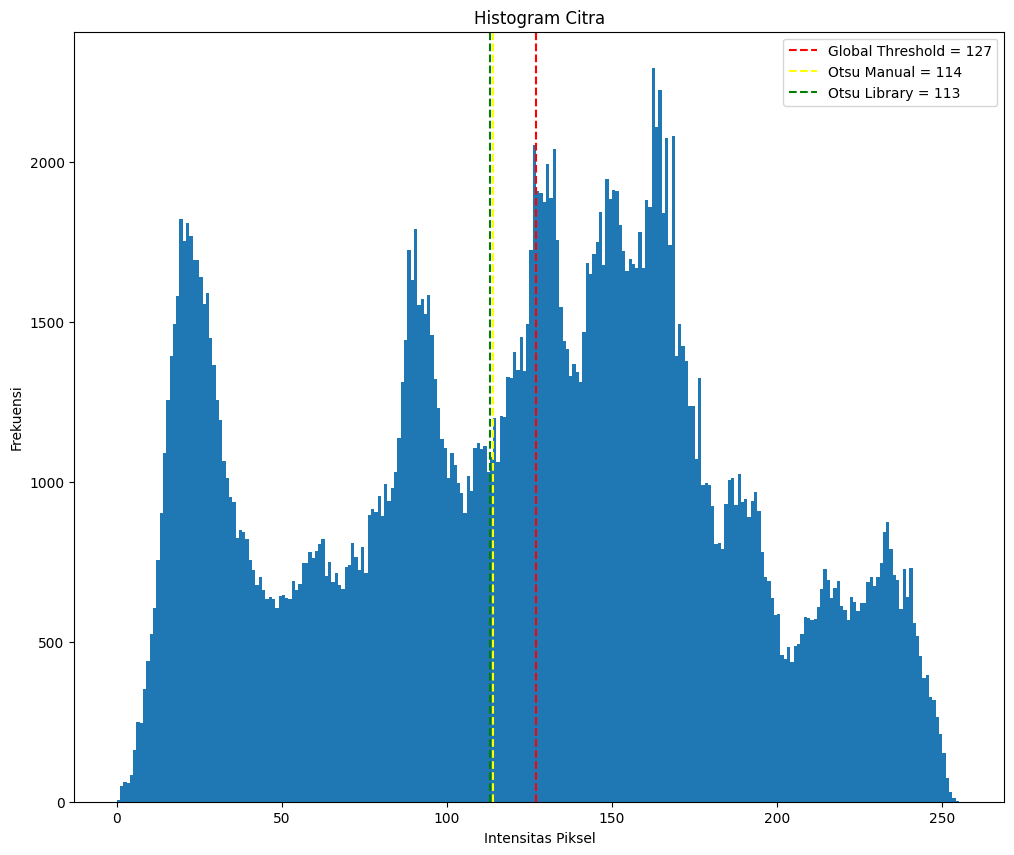

In [ ]:
plt.figure(figsize=(12, 10))

plt.hist(blur.ravel(), bins=256, range=[0, 256])

plt.axvline(127, color='red', linestyle='--', label='Global Threshold = 127')
plt.axvline(114, color='yellow', linestyle='--', label='Otsu Manual = 114')
plt.axvline(113, color='green', linestyle='--', label='Otsu Library = 113')

plt.title('Histogram Citra')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()

**Jawaban :** supaya foto Lena masih terlihat, T harus berada **di dalam rentang histogram** (di antara min dan max, kira-kira 86–107). Nilai yang paling baik ada di sekitar puncak pemisah dua kelompok, yaitu ±90–95 (Otsu = 93). T terlalu dekat min → hampir putih semua; T terlalu dekat max → hampir hitam semua.

**F. Coba dengan IMG KTP agar terlihat beda antara otsu's -> global threshold**

Otsu Threshold: 176


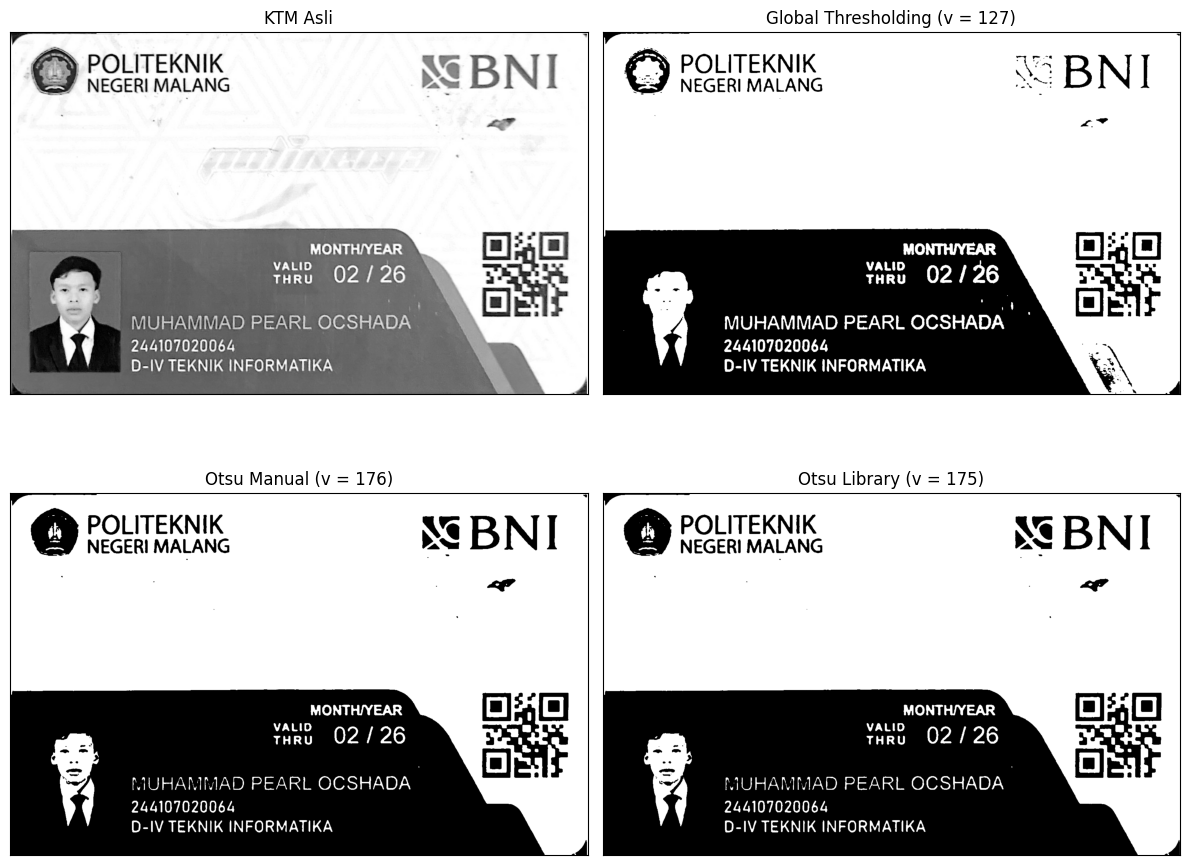

In [ ]:
# Membaca citra KTM dalam format grayscale
img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020064/KTM1b.jpg', 0)

# Lakukan Gaussian Blur
blur = cv.GaussianBlur(img, (5, 5), 0)

t = 127

# Global Thresholding
global_thres = np.where(blur > t, 255, 0).astype('uint8')

# Otsu Thresholding (Menggunakan fungsi manual otsu yang sudah didefinisikan sebelumnya)
otsu_manual, otsu_thresh = otsu(blur)
#Otsu Library
ret, otsu_library = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Menyiapkan data visualisasi khusus untuk KTM
ktm_images = [img, global_thres, otsu_manual, otsu_library]
ktm_titles = ['KTM Asli', 'Global Thresholding (v = 127)', f'Otsu Manual (v = {otsu_thresh})', f'Otsu Library (v = {int(ret)})']

plt.figure(figsize=(12, 10))
for i in range(len(ktm_images)):
    plt.subplot(2, 2, i+1)
    plt.imshow(ktm_images[i], 'gray')
    plt.title(ktm_titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

  **Membuat Histogram**

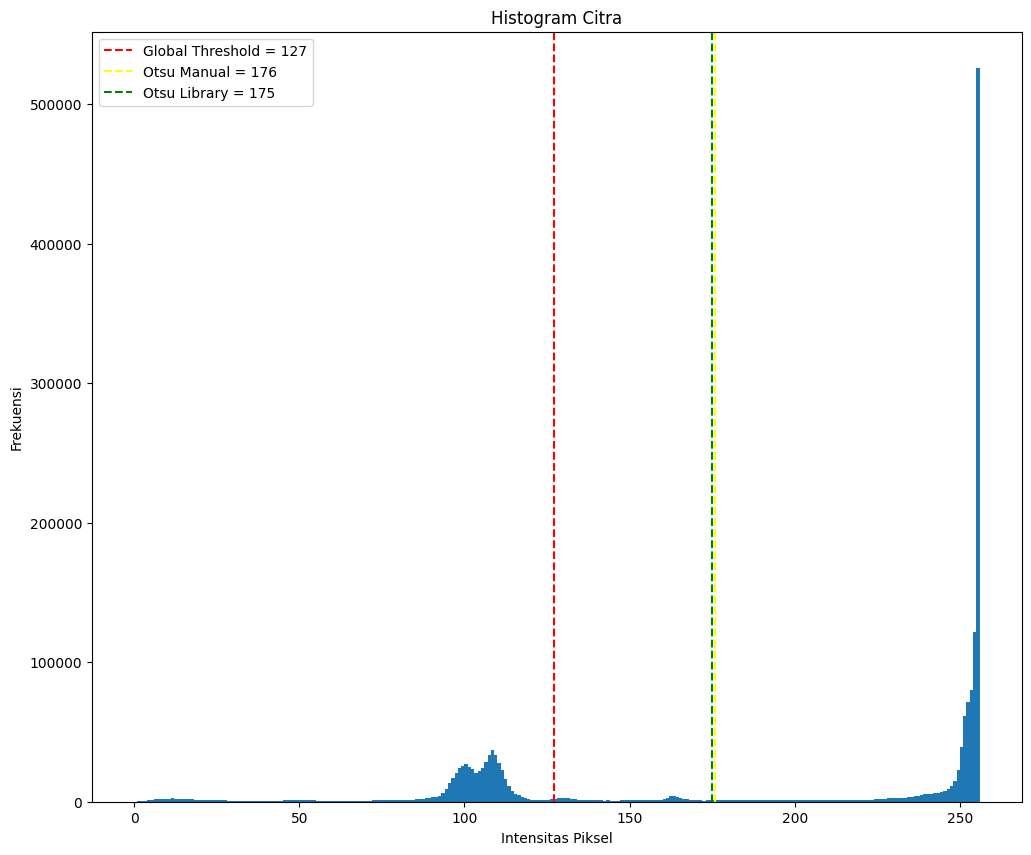

In [ ]:
plt.figure(figsize=(12, 10))

plt.hist(blur.ravel(), bins=256, range=[0, 256])

plt.axvline(127, color='red', linestyle='--', label='Global Threshold = 127')
plt.axvline(176, color='yellow', linestyle='--', label='Otsu Manual = 176')
plt.axvline(175, color='green', linestyle='--', label='Otsu Library = 175')

plt.title('Histogram Citra')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()

**G. Segmentasi berbasis Region**

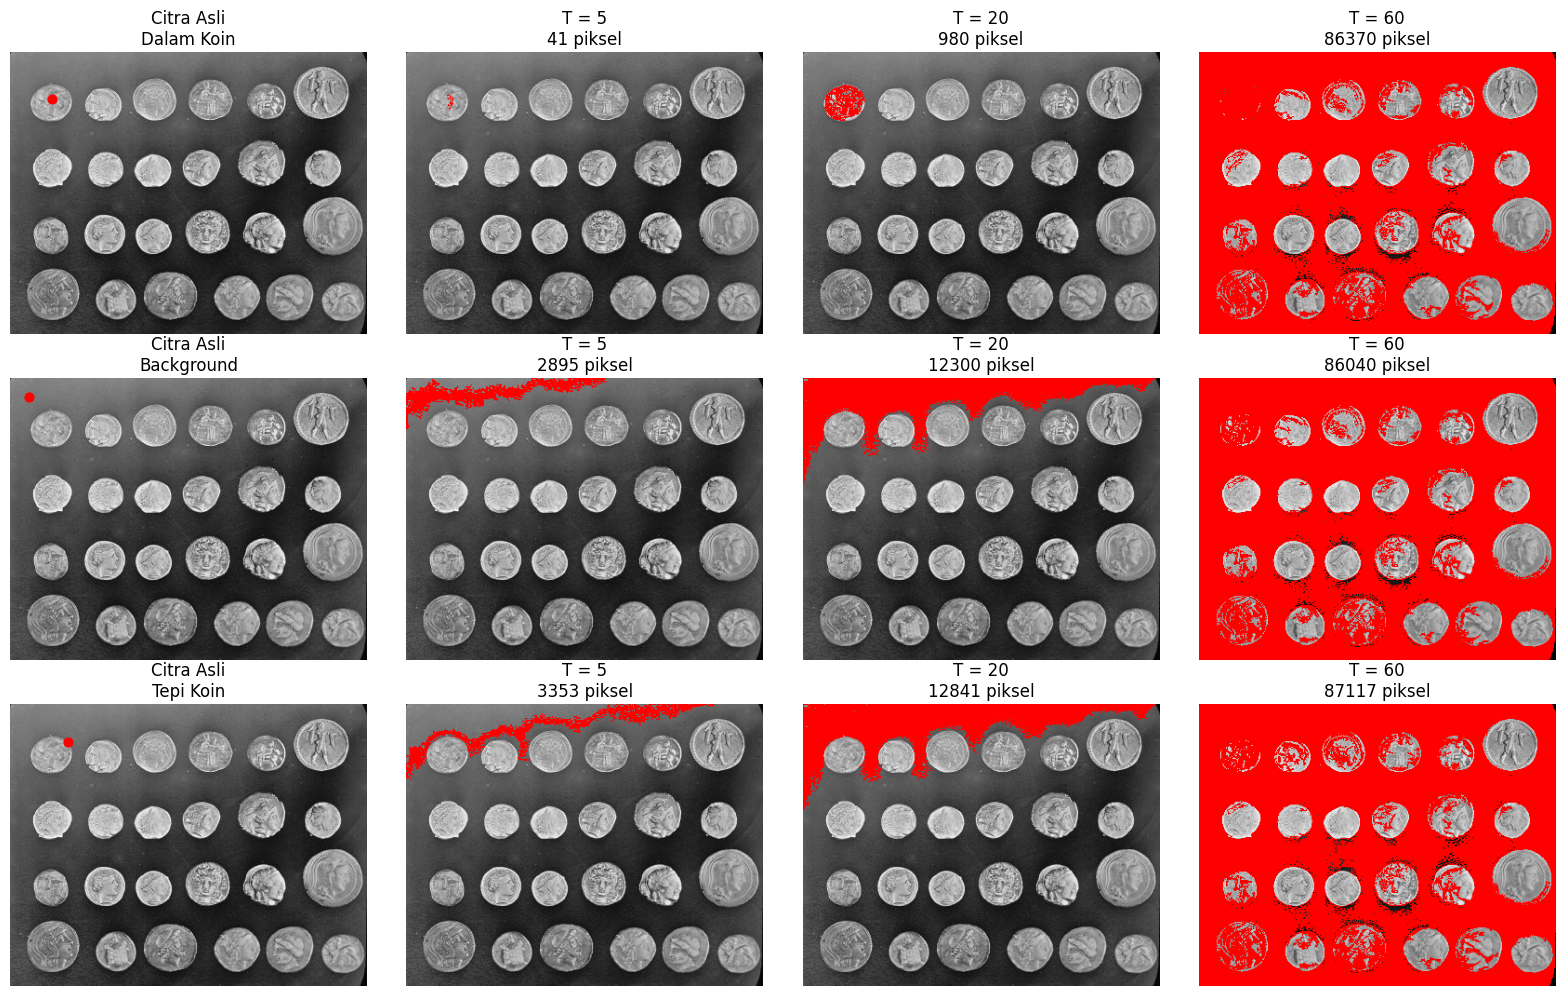

In [ ]:
img = data.coins()


seed_list = {
    "Dalam Koin": (50, 45),
    "Background": (20, 20),
    "Tepi Koin": (40, 62)
}


NEIGHBOR_8 = [
    (-1, -1), (-1, 0), (-1, 1),
    (0, -1),            (0, 1),
    (1, -1),  (1, 0),  (1, 1)
]

def grow_region(image, seed, threshold):

    height, width = image.shape

    # False = belum menjadi bagian region
    region = np.zeros((height, width), dtype=bool)

    # Queue untuk BFS
    queue = deque()
    queue.append(seed)

    # Seed langsung dimasukkan ke region
    region[seed] = True

    # Statistik region
    total_intensity = float(image[seed])
    pixel_count = 1

    while queue:

        current_r, current_c = queue.popleft()

        # Hitung rata-rata region saat ini
        region_mean = total_intensity / pixel_count

        # Periksa 8 tetangga
        for dr, dc in NEIGHBOR_8:

            new_r = current_r + dr
            new_c = current_c + dc

            # Pastikan koordinat masih berada di dalam gambar
            if not (0 <= new_r < height and 0 <= new_c < width):
                continue

            # Jika pixel sudah masuk region, lewati
            if region[new_r, new_c]:
                continue

            # Nilai pixel kandidat
            pixel_value = float(image[new_r, new_c])

            # Cek kemiripan dengan region
            difference = abs(pixel_value - region_mean)

            if difference < threshold:

                # Masukkan pixel ke region
                region[new_r, new_c] = True
                queue.append((new_r, new_c))

                # Update statistik region
                total_intensity += pixel_value
                pixel_count += 1

    return region, pixel_count

def create_overlay(image, region):

    # Grayscale → RGB
    overlay = cv.cvtColor(image, cv.COLOR_GRAY2RGB)

    # Region hasil diberi warna merah
    overlay[region] = [255, 0, 0]

    return overlay

threshold_values = [5, 20, 60]

fig, axes = plt.subplots(
    len(seed_list),
    len(threshold_values) + 1,
    figsize=(16, 10)
)


for row, (seed_name, seed_point) in enumerate(seed_list.items()):

    ax = axes[row, 0]

    ax.imshow(img, cmap='gray')

    ax.scatter(
        seed_point[1],
        seed_point[0],
        color='red',
        s=40
    )

    ax.set_title(
        f"Citra Asli\n{seed_name}"
    )

    ax.axis('off')

    for col, threshold in enumerate(threshold_values, start=1):

        region, pixel_count = grow_region(
            img,
            seed_point,
            threshold
        )

        result = create_overlay(
            img,
            region
        )

        ax = axes[row, col]

        ax.imshow(result)

        ax.set_title(
            f"T = {threshold}\n"
            f"{pixel_count} piksel"
        )

        ax.axis('off')


plt.tight_layout()
plt.show()

**H. Segmentasi Berbasis Region dengan flood**

Seed (baris, kolom): (36, 43) | intensitas: 159.000000


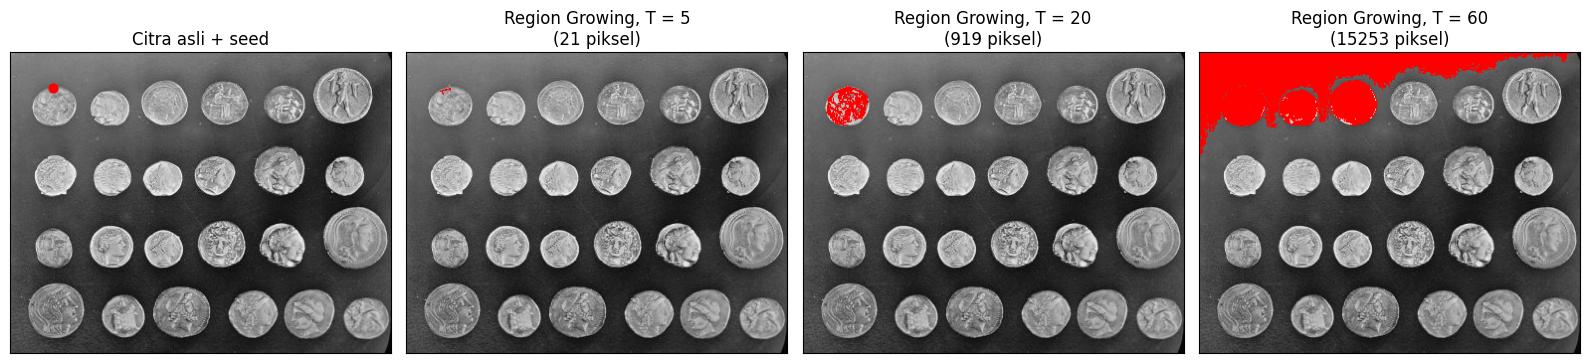

In [ ]:
# Citra coins
gray = data.coins()

# Seed
seed = (36, 43)

# Nilai toleransi
tolerances = [5, 20, 60]

# Menampilkan informasi seed
print(f"Seed (baris, kolom): {seed} | intensitas: {gray[seed]:.6f}")

plt.figure(figsize=(16, 4))

# Citra asli + seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.scatter(seed[1], seed[0], c='red', s=40)
plt.title('Citra asli + seed')
plt.xticks([])
plt.yticks([])


# Flood untuk setiap tolerance
for i, T in enumerate(tolerances):

    region = flood(
        gray,
        seed_point=seed,
        tolerance=T,
        connectivity=1
    )

    # Menghitung jumlah piksel region
    jumlah_piksel = np.sum(region)

    # Membuat citra RGB
    hasil = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)

    # Memberikan warna merah pada region
    hasil[region] = [255, 0, 0]

    plt.subplot(1, 4, i + 2)

    plt.imshow(hasil)

    plt.title(
        f'Region Growing, T = {T}\n'
        f'({jumlah_piksel} piksel)'
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

**I. Segmentasi Warna Biru pada Citra KTP Menggunakan K-Means dan HSV**

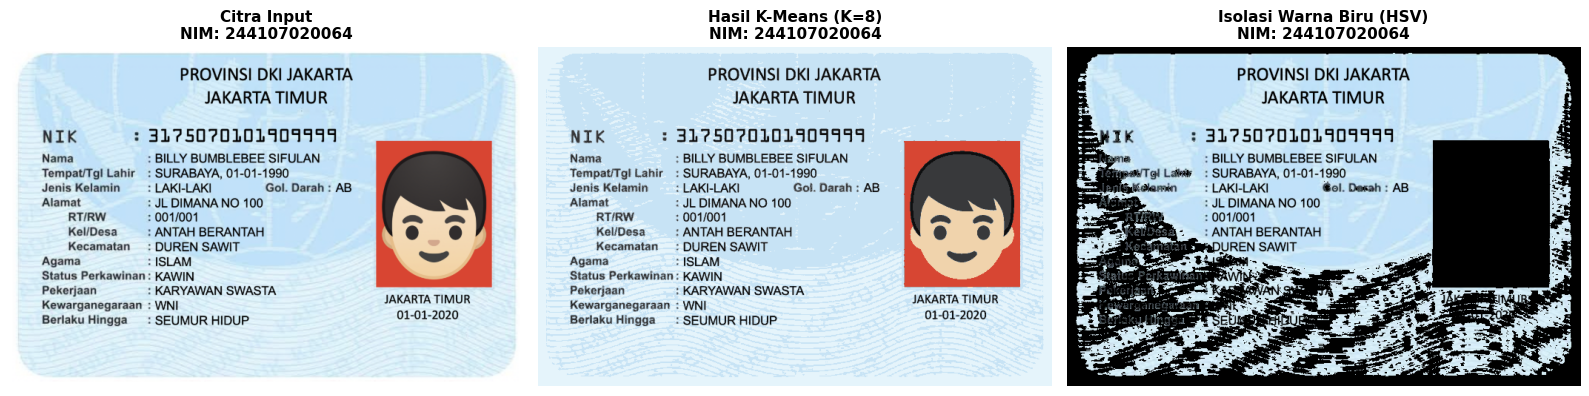

In [ ]:
# Membaca gambar KTP
citra_ktp = cv.imread('/content/drive/MyDrive/PCVK/P7/ktp_fulan.jpg')
citra_rgb = cv.cvtColor(citra_ktp, cv.COLOR_BGR2RGB)

# --- 1. SEGMENTASI MENGGUNAKAN K-MEANS CLUSTERING ---
# Meratakan dimensi gambar menjadi baris piksel
data_piksel = citra_rgb.reshape((-1, 3))
data_piksel = np.float32(data_piksel)

# Konfigurasi K-Means
jumlah_kluster = 8
kriteria_berhenti = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 15, 1.0)

# Proses clustering
_, label_piksel, pusat_warna = cv.kmeans(
    data_piksel,
    jumlah_kluster,
    None,
    kriteria_berhenti,
    10,
    cv.KMEANS_RANDOM_CENTERS
)

# Konversi pusat warna kembali ke uint8
pusat_warna = np.uint8(pusat_warna)
segmented_flat = pusat_warna[label_piksel.flatten()]
segmented_kmeans = segmented_flat.reshape(citra_rgb.shape)

# --- 2. EKSTRAKSI WARNA BIRU DENGAN RUANG WARNA HSV ---
citra_hsv = cv.cvtColor(citra_ktp, cv.COLOR_BGR2HSV)

# Definisikan batas warna biru (Low & High) secara presisi
batas_bawah_biru = np.array([90, 30, 30])
batas_atas_biru = np.array([130, 255, 255])

# Membuat masker biner untuk piksel biru
masker_biru = cv.inRange(citra_hsv, batas_bawah_biru, batas_atas_biru)

# Ekstrak objek berwarna biru dari citra asli
ekstraksi_biru = cv.bitwise_and(citra_ktp, citra_ktp, mask=masker_biru)
ekstraksi_biru_rgb = cv.cvtColor(ekstraksi_biru, cv.COLOR_BGR2RGB)

# --- 3. VISUALISASI HASIL PERBANDINGAN ---
fig, ax = plt.subplots(1, 3, figsize=(16, 6))

# Tampilan Citra Asli
ax[0].imshow(citra_rgb)
ax[0].set_title(f"Citra Input\nNIM: {NIM}", fontsize=11, fontweight='bold')
ax[0].axis('off')

# Tampilan Hasil K-Means
ax[1].imshow(segmented_kmeans)
ax[1].set_title(f"Hasil K-Means (K={jumlah_kluster})\nNIM: {NIM}", fontsize=11, fontweight='bold')
ax[1].axis('off')

# Tampilan Segmentasi Warna Biru
ax[2].imshow(ekstraksi_biru_rgb)
ax[2].set_title(f"Isolasi Warna Biru (HSV)\nNIM: {NIM}", fontsize=11, fontweight='bold')
ax[2].axis('off')

plt.tight_layout()
plt.show()

# **Kelompok - KTM tiap anggota, dengan 3 kategori**
1. Citra berwarna asli
2. Citra hasil segmentasi menggunakan otsu thresholding
3. Citra hasil segmentasi menggunakan adaptive thresholding

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocer-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
E: Unable to locate package tesseract-ocer-ind


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

PATH = "/content/drive/MyDrive/PCVK/Images/Kelompok"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


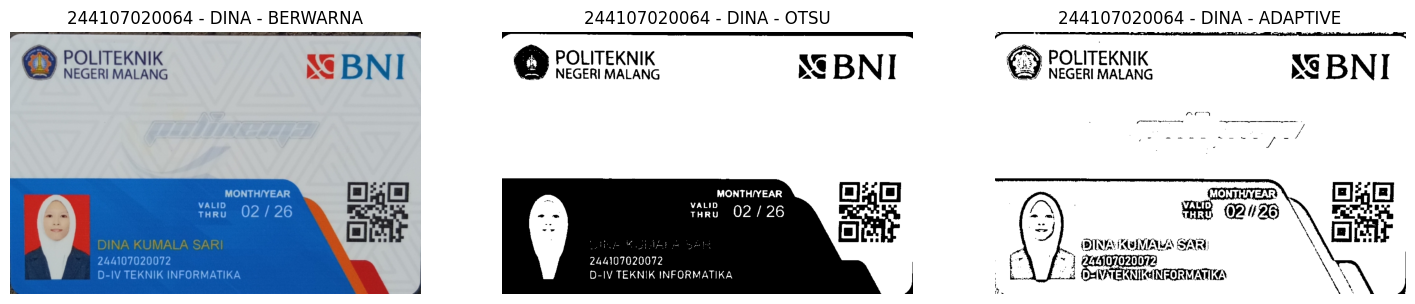

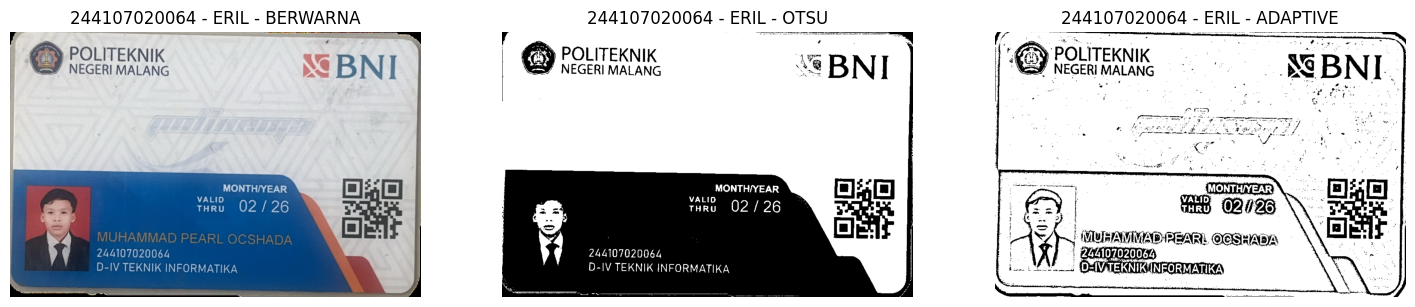

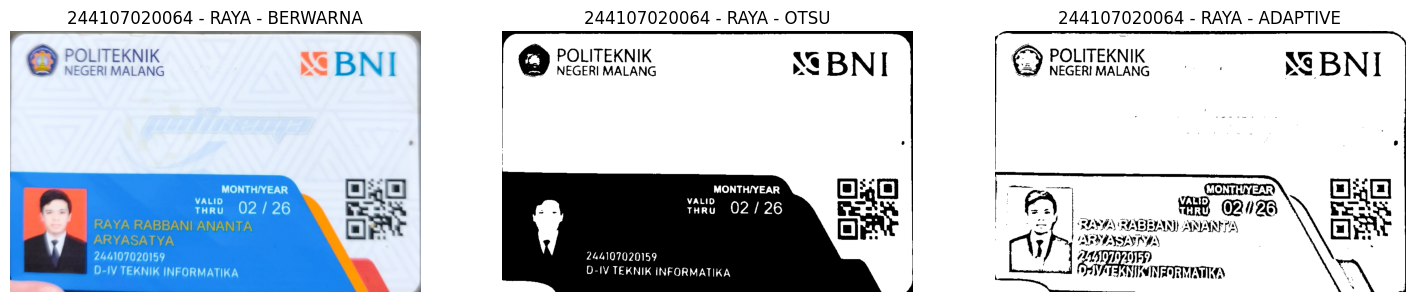

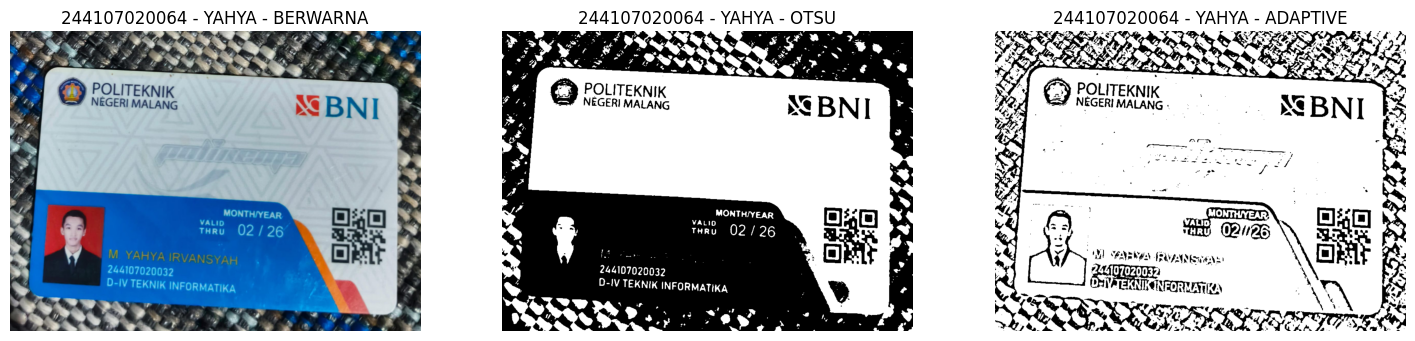

In [37]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import drive
drive.mount('/content/drive')

NAMA = 'Muhammad Pearl Ocshada'
NIM  = '244107020064'

BASE = '/content/drive/MyDrive/PCVK/Images/Kelompok'
anggota = ['dina', 'eril', 'raya', 'yahya']
LEBAR = 1000

def siapkan(nama):
    # Daftar ekstensi yang akan dicoba jika .jpg tidak ditemukan
    possible_extensions = ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']
    bgr = None
    img_path = ""

    for ext in possible_extensions:
        temp_path = f"{BASE}/KTM_{nama}{ext}"
        if os.path.exists(temp_path):
            img_path = temp_path
            bgr = cv.imread(img_path)
            if bgr is not None:
                break

    if bgr is None:
        raise FileNotFoundError(f"Gambar untuk {nama} tidak ditemukan di {BASE}/ dengan ekstensi apa pun. Silakan periksa nama file Anda di Google Drive.")

    h, w = bgr.shape[:2]
    bgr = cv.resize(bgr, (LEBAR, int(h * LEBAR / w)))
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
    _, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 10)
    return {'BERWARNA': bgr, 'OTSU': otsu, 'ADAPTIVE': adaptive}

try:
    data = {n: siapkan(n) for n in anggota}

    # Tampilkan tiga citra untuk dibandingkan
    for n in anggota:
        plt.figure(figsize=(18,5))
        for i, (k, c) in enumerate(data[n].items(), 1):
            plt.subplot(1,3,i)
            plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB) if c.ndim == 3 else c, cmap='gray')
            plt.title(NIM + ' - ' + n.upper() + ' - ' + k)
            plt.axis('off')
        plt.show()
except FileNotFoundError as e:
    print("Error:", e)

**Hasil Teks**

In [38]:
hasil_teks = {}
for n in anggota:
    print('#' * 20, n.upper(), '#' * 20)
    hasil_teks[n] = {}
    for k, c in data[n].items():
        teks = pytesseract.image_to_string(c, lang=LANG, config=CONFIG)
        hasil_teks[n][k] = teks
        print('=' * 10, k, '=' * 10)
        print(teks.strip())
        print()

#################### DINA ####################
========== BERWARNA ==========
ea wwawaaaaa—uwwwwwww:-
( y POLITEKNIK —-
@ NEGERI MALANG NG
: 2
0 DINA KUMALA SARI: a"
: ,

========== OTSU ==========
GG @$———.
POLITEKNIK -
@ 2LTEKNIK “BNI
MONTH/YEAR OrAD|
9 YUD 99/26 Et
D-IV TEKNIK INFORMATIKA ,

========== ADAPTIVE ==========
POLITEKNIK —
& NEGERI MALANG SBNI
| NN,
Nan DADI
| RB (2 1AG $ Se
P3 We MEROINAIKU MALAISARI N mr
AD Na
2. MR D-IV EK NIK NEORMATIKA AN

#################### ERIL ####################
========== BERWARNA ==========
4 "4 , »
'@j POLITEKNIK
& NEGERI MALANG BNI
MONTH/YEAR mj £ “|
YAH9 02 126 2
MUHAMMAD PEARI LADA Ol : |
244107020064
D-IV TEKNIK INFORMATIKA |

========== OTSU ==========
| POLITEKNIK gn
9 NEGERI MALANG sSBNI
MONTH/YEAR Oo |
| & YO 92 /26 PA |
X| 244107020064
D-IV TEKNIK INFORMATIKA |

========== ADAPTIVE ==========
GP KS TA“ N

(S3 POLITEKNIK ng GG

2 NEGERIMALANG "- SSBNI.
TA SAN NABI
. HB Was 2S|
ara MUA UNAPSEAR MO GS ADA ai
po #212107020064 ' SA
AA 

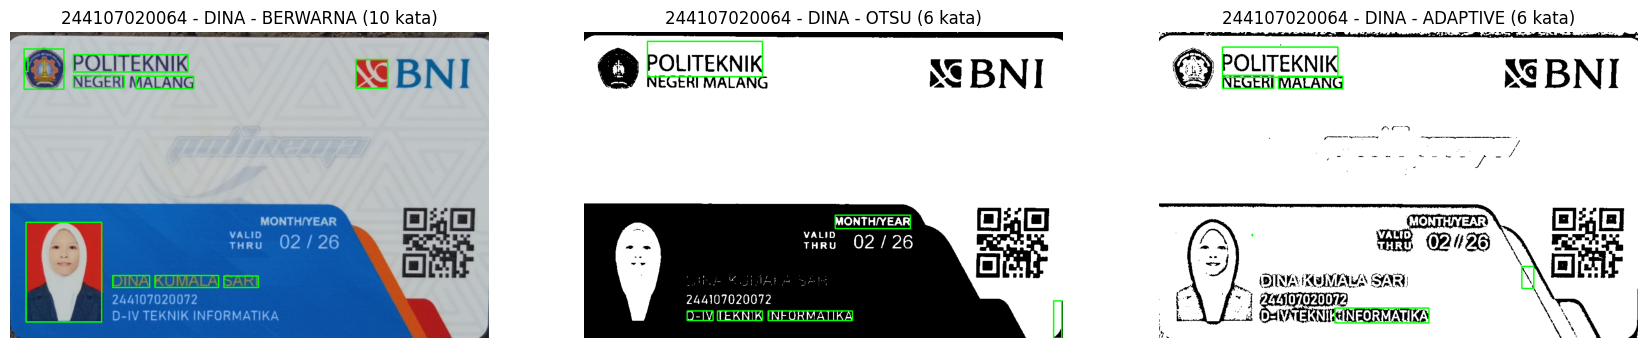

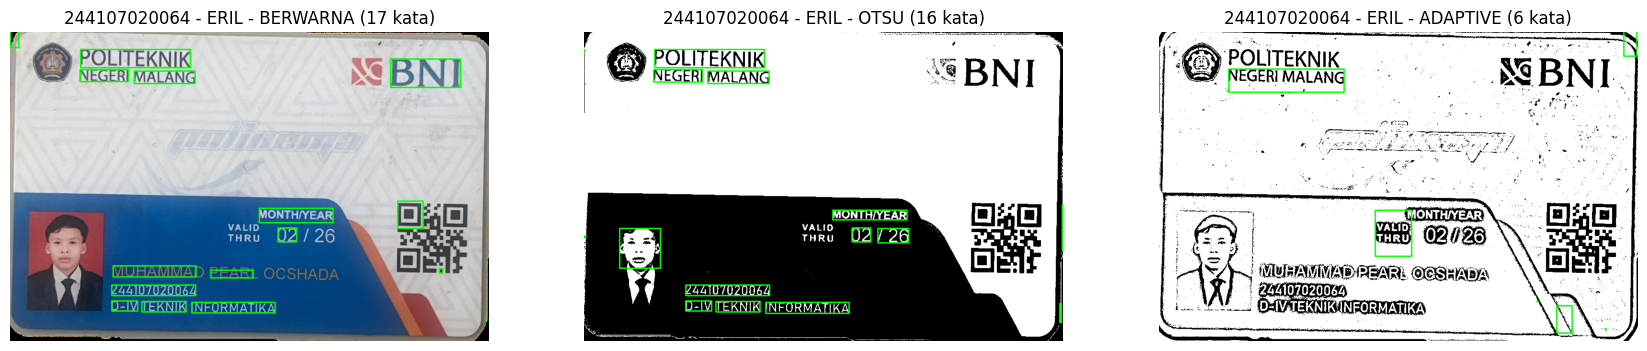

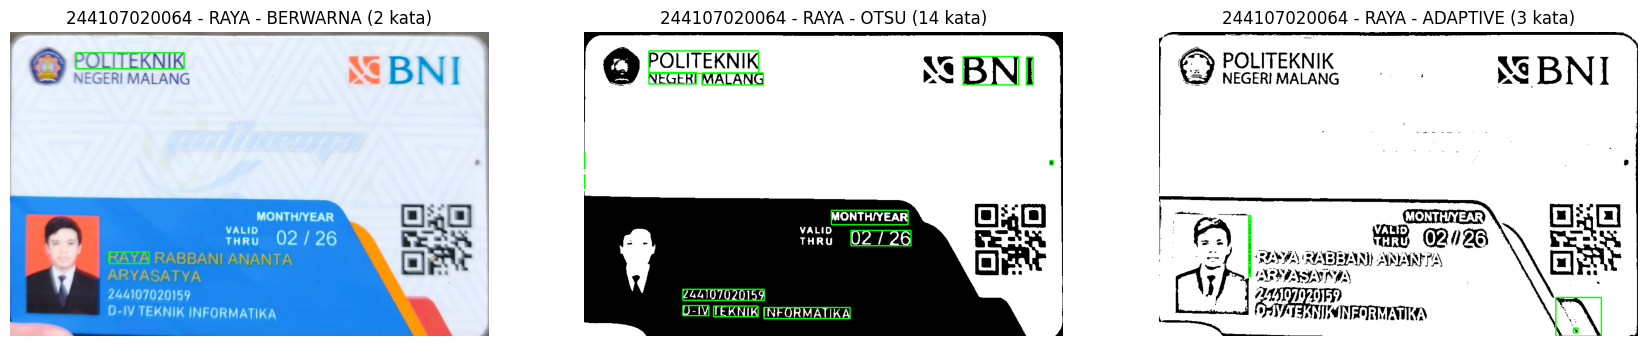

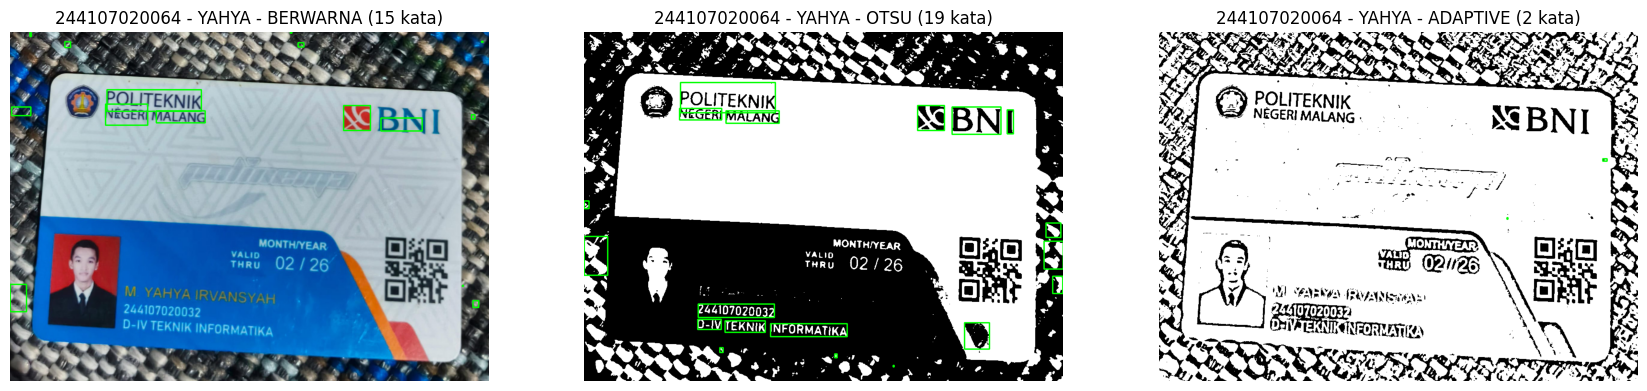

KTM      Citra      Rata-rata confidence
dina     BERWARNA   85.6
dina     OTSU       89.3
dina     ADAPTIVE   92.7
eril     BERWARNA   87.4
eril     OTSU       87.5
eril     ADAPTIVE   73.3
raya     BERWARNA   85.0
raya     OTSU       92.1
raya     ADAPTIVE   76.3
yahya    BERWARNA   79.4
yahya    OTSU       86.7
yahya    ADAPTIVE   88.5


In [39]:
rata_conf = {}
for n in anggota:
    plt.figure(figsize=(21,7))
    rata_conf[n] = {}
    for i, (k, c) in enumerate(data[n].items(), 1):
        d = pytesseract.image_to_data(c, lang=LANG, config=CONFIG,
                                      output_type=pytesseract.Output.DICT)
        vis = c.copy() if c.ndim == 3 else cv.cvtColor(c, cv.COLOR_GRAY2BGR)
        confs = []
        for j in range(len(d['text'])):
            conf = float(d['conf'][j])
            if conf > CONF_MIN and d['text'][j].strip():
                x, y, w, h = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
                cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
                confs.append(conf)
        rata_conf[n][k] = np.mean(confs) if confs else 0
        plt.subplot(1,3,i)
        plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB))
        plt.title(NIM + ' - ' + n.upper() + ' - ' + k + ' (' + str(len(confs)) + ' kata)')
        plt.axis('off')
    plt.show()

print('%-8s %-10s %s' % ('KTM', 'Citra', 'Rata-rata confidence'))
for n in anggota:
    for k in data[n]:
        print('%-8s %-10s %.1f' % (n, k, rata_conf[n][k]))

In [40]:
!pip install tabulate

In [46]:
from tabulate import tabulate

data_eril = [
    ["Berwarna Asli", "NIM, D-IV TEKNIK INFORMATIKA (Nama terbaca sebagian/salah: PEARI LADA)", "70%", "87.4%"],
    ["Segmentasi Otsu", "POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA", "90%", "87.5%"],
    ["Segmentasi Adaptive", "NIM, D-IV TEKNIK INFORMATIKA (Teks dipenuhi noise karakter luar)", "50%", "73.3%"]
]

kolom = ["Citra masukan OCR (ERIL)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]

print(tabulate(data_eril, headers=kolom, tablefmt="grid"))
print("\n")

data_dina = [
    ["Berwarna Asli", "DINA KUMALA SARI (Nama terbaca sebagian/ada noise)", "60%", "85.6%"],
    ["Segmentasi Otsu", "POLITEKNIK, BNI, D-IV TEKNIK INFORMATIKA (Nama terpotong)", "75%", "89.3%"],
    ["Segmentasi Adaptive", "POLITEKNIK NEGERI MALANG, BNI, DINA KUMALA SARI, D-IV TEKNIK INFORMATIKA", "85%", "92.7%"]
]
kolom_dina = ["Citra masukan OCR (DINA)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]
print(tabulate(data_dina, headers=kolom_dina, tablefmt="grid"))
print("\n")


data_raya = [
    ["Berwarna Asli", "RAYA (Hanya terbaca bagian depan nama)", "40%", "85.0%"],
    ["Segmentasi Otsu", "POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA", "90%", "92.1%"],
    ["Segmentasi Adaptive", "POLITEKNIK NEGERI MALANG, BNI, RAYA RABBANI ANANTA ARYASATYA", "80%", "76.3%"]
]
kolom_raya = ["Citra masukan OCR (RAYA)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]
print(tabulate(data_raya, headers=kolom_raya, tablefmt="grid"))
print("\n")

data_yahya = [
    ["Berwarna Asli", "YAHYAIRVANSYARI (Sangat minim terbaca karena noise anyaman background)", "30%", "79.4%"],
    ["Segmentasi Otsu", "POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA", "85%", "86.7%"],
    ["Segmentasi Adaptive", "D-IV TEKNIK INFORMATIKA (Sangat banyak noise karena anyaman background)", "40%", "88.5%"]
]
kolom_yahya = ["Citra masukan OCR (YAHYA)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]
print(tabulate(data_yahya, headers=kolom_yahya, tablefmt="grid"))

+----------------------------+------------------------------------------------------------------------+-----------------+------------------------+
| Citra masukan OCR (ERIL)   | Item terbaca tepat                                                     | Kecocokan (%)   | Rata-rata confidence   |
+============================+========================================================================+=================+========================+
| Berwarna Asli              | NIM, D-IV TEKNIK INFORMATIKA (Nama terbaca sebagian/salah: PEARI LADA) | 70%             | 87.4%                  |
+----------------------------+------------------------------------------------------------------------+-----------------+------------------------+
| Segmentasi Otsu            | POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA            | 90%             | 87.5%                  |
+----------------------------+------------------------------------------------------------------------+---------------

### 1. Citra masukan mana yang menghasilkan pembacaan paling tepat?

Berdasarkan hasil percobaan kelompok kami, citra yang menghasilkan pembacaan paling baik ternyata berbeda-beda pada setiap KTM. Namun, secara umum, metode **Otsu memberikan hasil yang cukup baik pada KTM dengan latar belakang yang lebih sederhana**.

Hal ini bisa dilihat dari hasil pengujian KTM Eril dan KTM Raya yang sama-sama memperoleh tingkat kecocokan sebesar 90% menggunakan metode Otsu. Pada KTM Eril, metode ini mampu membaca beberapa informasi penting, seperti nama politeknik, BNI, NIM, dan program studi D-IV Teknik Informatika.

Sementara itu, pada KTM Raya, metode Otsu juga mampu mengenali sebagian besar teks dengan hasil yang cukup baik.

Meskipun begitu, hasil berbeda ditemukan pada KTM Dina. Metode Adaptive Thresholding justru memberikan hasil terbaik dengan tingkat kecocokan sebesar 85%. Hal ini menunjukkan bahwa metode yang paling baik tidak selalu sama untuk setiap citra, karena hasilnya juga dipengaruhi oleh kondisi gambar dan latar belakangnya.

### 2. Sebutkan minimal dua kesalahan pembacaan OCR!

Selama percobaan, kami menemukan beberapa kesalahan pembacaan teks oleh Tesseract OCR.

- **Kesalahan membaca huruf pada nama Eril.** Pada citra berwarna asli, nama `MUHAMMAD PEARL OCSHADA` terbaca menjadi `MUHAMMAD PEARI LADA`. Beberapa huruf salah dikenali atau bahkan tidak terbaca, sehingga hasilnya berbeda dari teks asli.
- **Nama pada KTM Raya tidak terbaca lengkap.** Ketika menggunakan citra berwarna asli, OCR hanya berhasil membaca kata `RAYA`, sedangkan bagian nama lainnya tidak terdeteksi dengan baik.
- **Munculnya karakter acak pada KTM Yahya.** Penggunaan Adaptive Thresholding menghasilkan teks yang tidak jelas, seperti `AA A3 CO Pa KAA TAG...`. Hal ini kemungkinan disebabkan oleh pola latar belakang yang ikut terbaca sebagai karakter oleh OCR.

Dari beberapa kesalahan tersebut, dapat diketahui bahwa OCR masih bisa mengalami kesulitan dalam membedakan teks dengan elemen lain yang ada pada gambar.

### 3. Apakah segmentasi selalu meningkatkan ketepatan OCR?

Menurut hasil percobaan kelompok kami, segmentasi **tidak selalu meningkatkan ketepatan pembacaan OCR**. Pengaruhnya bergantung pada metode yang digunakan dan kondisi citra yang diproses.

Sebagai contoh, metode Otsu memberikan hasil yang baik pada KTM Eril dan KTM Raya dengan tingkat kecocokan masing-masing sebesar 90%. Metode ini membantu memisahkan teks dari latar belakang sehingga tulisan lebih mudah dikenali.

Namun, hasil berbeda terlihat pada KTM Yahya. Penggunaan Adaptive Thresholding justru menyebabkan pola anyaman pada latar belakang menjadi lebih jelas dalam bentuk hitam-putih. Akibatnya, pola tersebut ikut dianggap sebagai bagian dari teks dan membuat hasil pembacaan menjadi kurang akurat, dengan tingkat kecocokan sebesar 40%.

Dari hasil tersebut, kami menyimpulkan bahwa segmentasi memang dapat membantu proses OCR, tetapi tidak selalu menghasilkan pembacaan yang lebih baik. Pemilihan metode harus disesuaikan dengan karakteristik gambar yang digunakan.

### 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

Warna dan pola latar belakang cukup berpengaruh terhadap hasil pembacaan OCR. Hal ini karena OCR perlu membedakan tulisan dengan bagian lain yang terdapat pada citra.

Pada KTM Yahya, latar belakang yang memiliki pola anyaman membuat proses segmentasi menjadi lebih sulit. Pola tersebut dapat ikut terdeteksi sebagai objek ketika gambar diubah menjadi hitam-putih. Akibatnya, muncul banyak noise yang mengganggu proses pengenalan teks.

Selain itu, perbedaan warna antara teks dan latar belakang juga berpengaruh. Pada bagian KTM yang memiliki gradasi biru dan putih, kontras antara tulisan dengan latar belakang bisa menjadi kurang jelas. Kondisi ini berpotensi menyebabkan beberapa huruf salah dikenali atau bahkan tidak terbaca.

Dengan demikian, citra yang memiliki tulisan jelas, kontras yang baik, dan latar belakang sederhana cenderung lebih mudah diproses oleh OCR dibandingkan citra dengan pola yang ramai atau kontras yang rendah.

### 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Berdasarkan hasil percobaan, rata-rata confidence yang tinggi tidak selalu menunjukkan bahwa hasil pembacaan OCR paling sesuai dengan teks aslinya.

Contohnya, pada KTM Dina menggunakan Adaptive Thresholding, rata-rata confidence mencapai 92,7%, sedangkan tingkat kecocokannya sebesar 85%. Di sisi lain, KTM Eril menggunakan metode Otsu memperoleh confidence sebesar 87,5%, tetapi tingkat kecocokannya mencapai 90%.

Hasil tersebut menunjukkan bahwa confidence dan tingkat kecocokan mengukur dua hal yang berbeda. Confidence menunjukkan tingkat keyakinan Tesseract terhadap hasil pengenalan karakter atau kata, sedangkan tingkat kecocokan menunjukkan seberapa sesuai hasil pembacaan dengan teks asli yang dijadikan acuan.

Oleh karena itu, metode dengan confidence tertinggi belum tentu menghasilkan teks yang paling akurat. Untuk menentukan metode terbaik, kita perlu melihat hasil pembacaan teks, tingkat kecocokan, dan nilai confidence secara bersamaan.